In [2]:
import math
import sys
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import torch

In [3]:
try:
    ROOT = Path(__file__).resolve().parent
except NameError:  # exécution dans une cellule Jupyter : `__file__` n'existe pas
    ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
FIGURES_DIR = ROOT / "figures"
NAMES_URL = "https://raw.githubusercontent.com/karpathy/makemore/master/names.txt"

In [5]:
def load_text(path: Path, url: str) -> str:
    """
    Lit un fichier texte, en le téléchargeant d'abord s'il est absent.
    Retourne le contenu du fichier, décodé en UTF-8.
    """
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        print(f"téléchargement de {url}")
        urllib.request.urlretrieve(url, path)
    return path.read_text(encoding="utf-8")

## 1. Les données

Un prénom par ligne. Chaque prénom est **un petit texte** : le modèle doit
apprendre à quoi ressemble un prénom, lettre par lettre, puis en inventer de
nouveaux. On change de corpus par rapport au script 01 parce que les prénoms
sont courts : on voit tout, on compte tout, et les tableaux restent petits.

In [6]:
words = load_text(DATA_DIR / "names.txt", NAMES_URL).splitlines()
print(f"{len(words):,} prénoms   ex. {words[:8]}")
print(f"longueur min {min(len(w) for w in words)}   max {max(len(w) for w in words)}")

32,033 prénoms   ex. ['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']
longueur min 2   max 15


## 2. Les bigrammes

Un **bigramme** est une paire de caractères consécutifs. Le modèle bigramme
fait une hypothèse radicale : **le prochain caractère ne dépend que du
caractère courant**. Tout le reste du passé est ignoré.
Un prénom contient aussi deux informations cachées : par quelle lettre il
commence, et quand il s'arrête. On les rend explicites avec des marqueurs de
début `<S>` et de fin `<E>`

In [7]:
counts: Counter[tuple[str, str]] = Counter()
for w in words:
    chs = ["<S>", *w, "<E>"]
    for ch1, ch2 in zip(chs, chs[1:]):
        counts[(ch1, ch2)] += 1

print(f"{len(counts)} bigrammes distincts")
for pair, c in counts.most_common(10):
    print(f"  {pair}  {c}")

627 bigrammes distincts
  ('n', '<E>')  6763
  ('a', '<E>')  6640
  ('a', 'n')  5438
  ('<S>', 'a')  4410
  ('e', '<E>')  3983
  ('a', 'r')  3264
  ('e', 'l')  3248
  ('r', 'i')  3033
  ('n', 'a')  2977
  ('<S>', 'k')  2963


Beaucoup de prénoms finissent par `n` ou `a`, beaucoup commencent par `a`.
Le dictionnaire contient déjà tout le « savoir » du modèle.

## 3. Les comptes dans un tenseur

Un tenseur est plus pratique qu'un dictionnaire : une ligne par caractère
courant, une colonne par caractère suivant.

N28 : (28, 28)   lignes vides : ['<E>']   colonnes vides : ['<S>']


Text(0.5, 1.0, '28 symboles : la ligne <E> et la colonne <S> sont vides')

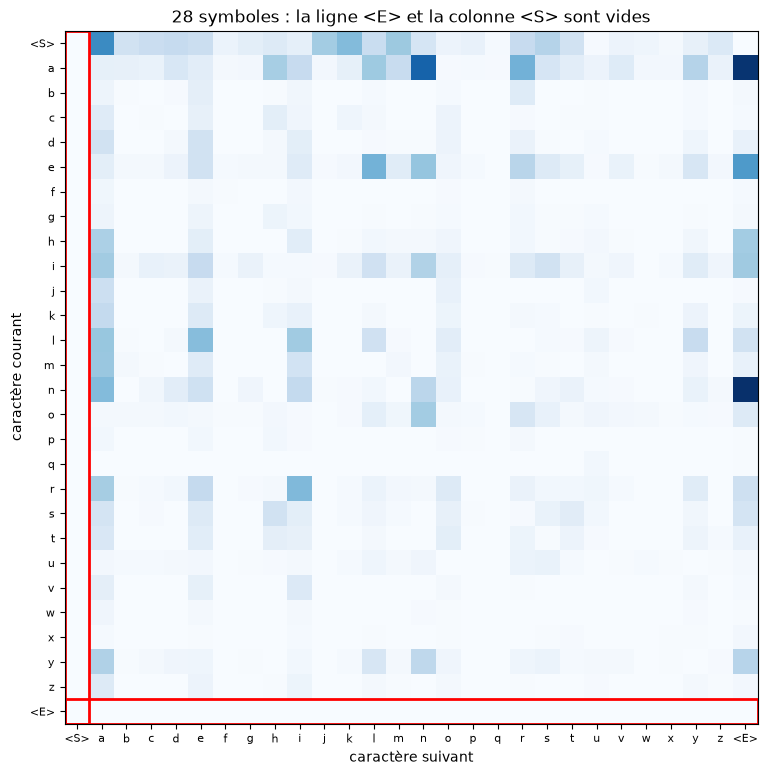

In [9]:
symbols = ["<S>", *sorted(set("".join(words))), "<E>"]
stoi28 = {s: i for i, s in enumerate(symbols)}

N28 = torch.zeros((len(symbols), len(symbols)), dtype=torch.int32)
for (ch1, ch2), c in counts.items():
    N28[stoi28[ch1], stoi28[ch2]] = c

empty_rows = [symbols[i] for i in range(len(symbols)) if N28[i].sum() == 0]
empty_cols = [symbols[j] for j in range(len(symbols)) if N28[:, j].sum() == 0]
print(f"N28 : {tuple(N28.shape)}   lignes vides : {empty_rows}   colonnes vides : {empty_cols}")

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(N28, cmap="Blues")
ax.set_xticks(range(len(symbols)), symbols, fontsize=8)
ax.set_yticks(range(len(symbols)), symbols, fontsize=8)
ax.set_xlabel("caractère suivant")
ax.set_ylabel("caractère courant")
# encadre en rouge la ligne <E> et la colonne <S>, toujours à zéro
last = len(symbols) - 1
ax.add_patch(plt.Rectangle((-0.5, last - 0.5), len(symbols), 1, fill=False, ec="red", lw=2))
ax.add_patch(plt.Rectangle((-0.5, -0.5), 1, len(symbols), fill=False, ec="red", lw=2))
ax.set_title("28 symboles : la ligne <E> et la colonne <S> sont vides")


On fait une simplification :
un seul marqueur `.` joue à la fois le rôle de début et de fin. On passe de
28 à **27 symboles** (26 lettres et le point), et plus aucune ligne ni
colonne n'est inutile.

In [8]:
chars = sorted(set("".join(words)))
stoi = {ch: i + 1 for i, ch in enumerate(chars)}
stoi["."] = 0
itos = {i: ch for ch, i in stoi.items()}
vocab_size = len(stoi)

N = torch.zeros((vocab_size, vocab_size), dtype=torch.int32)
for w in words:
    chs = [".", *w, "."]
    for ch1, ch2 in zip(chs, chs[1:]):
        N[stoi[ch1], stoi[ch2]] += 1

print(f"N : {tuple(N.shape)}   total = {N.sum().item():,} bigrammes")

N : (27, 27)   total = 228,146 bigrammes


(np.float64(-0.5), np.float64(26.5), np.float64(26.5), np.float64(-0.5))

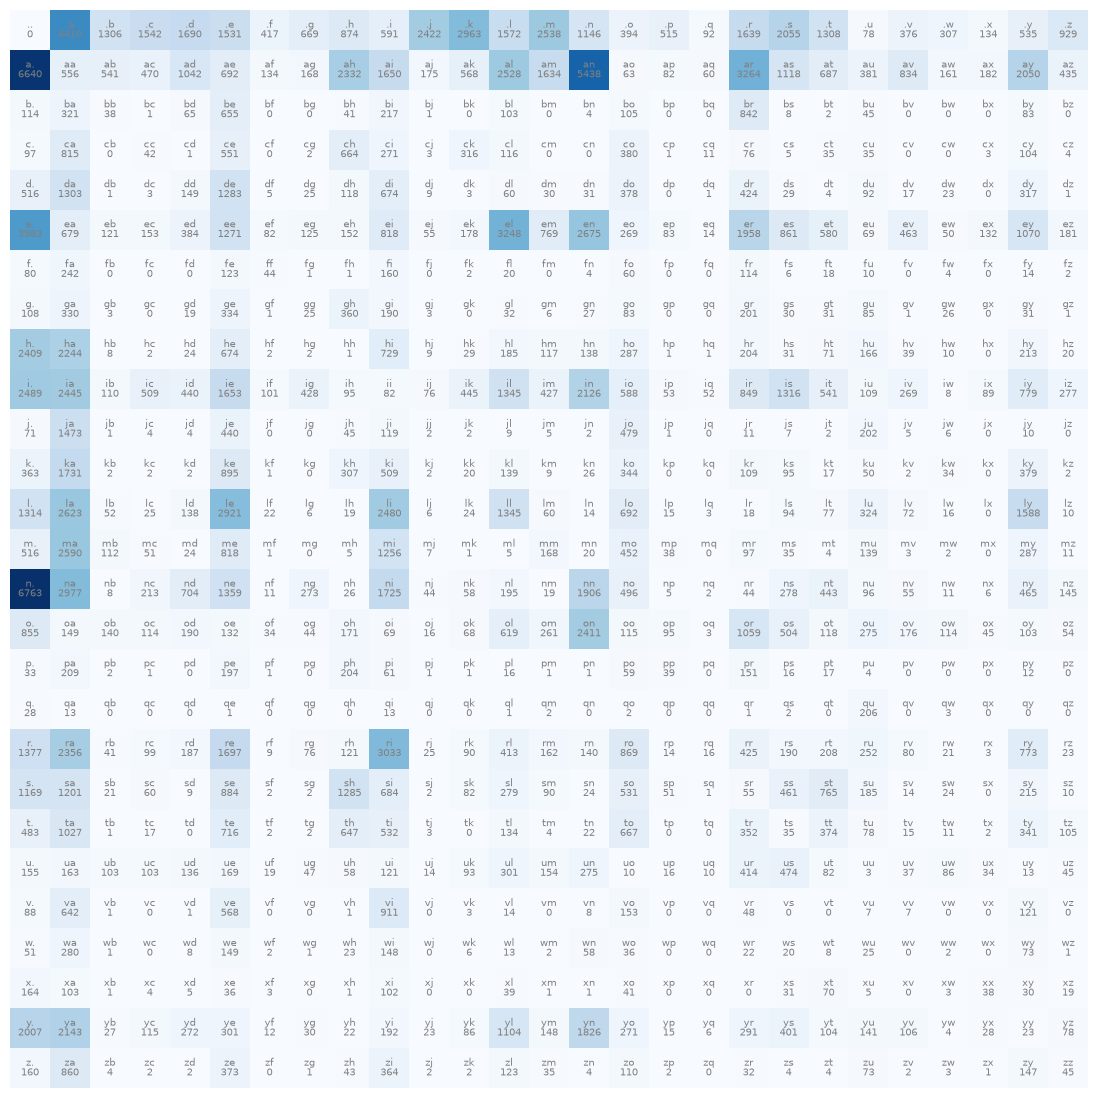

In [10]:
fig, ax = plt.subplots(figsize=(14, 14))
ax.imshow(N, cmap="Blues")
for i in range(vocab_size):
    for j in range(vocab_size):
        ax.text(j, i, itos[i] + itos[j], ha="center", va="bottom", color="gray", fontsize=7)
        ax.text(j, i, N[i, j].item(), ha="center", va="top", color="gray", fontsize=7)
ax.axis("off")

La carte se lit ligne par ligne : la ligne `q` est presque vide sauf en `u`,
la ligne `.` (début de prénom) montre les initiales, la colonne `.` les
dernières lettres. Certaines cases sont à **zéro** : ces paires n'existent
jamais dans les données. On y revient au chapitre 7.

## 4. Des comptes aux probabilités

On normalise chaque ligne pour qu'elle somme à 1 : la ligne `i` devient la
distribution du caractère suivant sachant le caractère `i`. Attention au
**broadcasting** : `keepdim=True` garde une forme `(27, 1)` qui divise
chaque ligne par sa somme. Sans lui, la forme `(27,)` diviserait chaque
**colonne**, sans aucune erreur, et le modèle serait faux.

In [12]:
import torch

M = torch.tensor([[1., 1., 2.],
                  [3., 0., 1.],
                  [0., 2., 0.]])

s_keep = M.sum(dim=1, keepdim=True)
s_flat = M.sum(dim=1)
print(s_keep.shape, s_flat.shape)   # torch.Size([3, 1]) torch.Size([3])
print(s_keep)                        # [[4.], [4.], [2.]]  -> une colonne
print(s_flat)                        # [4., 4., 2.]        -> un vecteur à plat

print(M / s_keep)
print((M / s_keep).sum(dim=1))       # [1., 1., 1.] 

print(M / s_flat)
print((M / s_flat).sum(dim=1))       # [1.50, 1.25, 0.50]  

torch.Size([3, 1]) torch.Size([3])
tensor([[4.],
        [4.],
        [2.]])
tensor([4., 4., 2.])
tensor([[0.2500, 0.2500, 0.5000],
        [0.7500, 0.0000, 0.2500],
        [0.0000, 1.0000, 0.0000]])
tensor([1., 1., 1.])
tensor([[0.2500, 0.2500, 1.0000],
        [0.7500, 0.0000, 0.5000],
        [0.0000, 0.5000, 0.0000]])
tensor([1.5000, 1.2500, 0.5000])


In [11]:
P = N.float()
P /= P.sum(dim=1, keepdim=True)
print(f"chaque ligne somme à 1 : {torch.allclose(P.sum(dim=1), torch.ones(vocab_size))}")

wrong = N.float() / N.float().sum(dim=1)
print(f"sans keepdim, les lignes somment à 1 ? {torch.allclose(wrong.sum(dim=1), torch.ones(vocab_size))}")

chaque ligne somme à 1 : True
sans keepdim, les lignes somment à 1 ? False


## 5. Générer

On part de `.`, on tire le caractère suivant selon la ligne correspondante
(`torch.multinomial`), on recommence depuis ce caractère, jusqu'à retomber
sur `.`. C'est **exactement** la boucle de génération d'un GPT : seul le
calcul de la distribution changera.

In [15]:
g = torch.Generator().manual_seed(2147483647)


def sample_bigram(probs: torch.Tensor, generator: torch.Generator) -> str:
    """Génère un prénom en tirant un caractère après l'autre.

    Args:
        probs: Matrice `(27, 27)` dont la ligne `i` est la distribution du
            caractère qui suit le caractère `i`.
        generator: Générateur aléatoire, pour des tirages reproductibles.

    Returns:
        Le prénom généré, sans le point final.
    """
    out = []
    ix = 0
    while True:
        ix = torch.multinomial(probs[ix], num_samples=1, replacement=True, generator=generator).item()
        if ix == 0:
            break
        out.append(itos[ix])
    return "".join(out)


print("bigramme :", [sample_bigram(P, g) for _ in range(10)])

uniform = torch.ones(vocab_size, vocab_size) / vocab_size
print("uniforme :", [sample_bigram(uniform, g) for _ in range(5)])

bigramme : ['cexze', 'momasurailezitynn', 'konimittain', 'llayn', 'ka', 'da', 'staiyaubrtthrigotai', 'moliellavo', 'ke', 'teda']
uniforme : ['kkjemkmmsidguenkbvgynywftbspmhwcivgbvtahlvsu', 'dsdxxblnwglhpyiw', 'igwnjwrpfdwipkwzkm', 'desu', 'firmt']


Les prénoms du bigramme sont mauvais, mais ils ont **quelque chose** de
prénom : longueurs plausibles, alternance voyelles / consonnes. Ceux du
modèle uniforme sont interminables et imprononçables. Le bigramme a appris
quelque chose ; reste à le **mesurer**, plutôt qu'à l'apprécier à l'œil.

## 6. Mesurer : la negative log likelihood

Un bon modèle donne une **forte probabilité** à ce qui arrive vraiment. On
multiplie donc les probabilités que le modèle attribue à chaque bigramme réel
du jeu de données : c'est la **vraisemblance**. 

Explication technique un peu barbare : Le produit de 228 000
nombres inférieurs à 1 vaut zéro en flottant ; on passe au logarithme, qui
transforme le produit en somme. On prend l'opposé (pour minimiser) et la
moyenne (pour ne pas dépendre de la taille du corpus).

C'est la **NLL**, et c'est exactement la `cross_entropy` de PyTorch déjà
tilisée sur MNIST : ici, on la calcule à la main.

In [17]:
def nll(probs: torch.Tensor, words_: list[str]) -> float:
    """negative log likelihood moyenne d'une liste de prénoms.

    Args:
        probs: Matrice de transition `(27, 27)`.
        words_: Prénoms sur lesquels évaluer le modèle.

    Returns:
        La NLL moyenne par bigramme.
    """
    log_likelihood = 0.0
    n = 0
    for w in words_:
        chs = [".", *w, "."]
        for ch1, ch2 in zip(chs, chs[1:]):
            log_likelihood += torch.log(probs[stoi[ch1], stoi[ch2]]).item()
            n += 1
    return -log_likelihood / n


print(f"NLL modèle uniforme : {nll(uniform, words):.4f}   (= ln 27 = {math.log(27):.4f})")
print(f"NLL bigramme        : {nll(P, words):.4f}")

NLL modèle uniforme : 3.2958   (= ln 27 = 3.2958)
NLL bigramme        : 2.4540


Le modèle uniforme sert de **référence** : `ln(27)`, c'est la loss d'un
modèle qui ne sait rien. Même réflexe qu'en séance 1 où la loss de départ
d'un classifieur à 10 classes valait `ln(10)`. Le bigramme descend nettement
en dessous : c'est le chiffre à battre pour tous les modèles qui suivent.

−ln(p) = −ln(1/27) = ln(27) ≈ 3,30.

## 7. Le lissage

Que vaut la NLL d'un prénom qui contient une paire jamais vue ?

In [18]:
for w in ["andrej", "nathan", "andrejq"]:
    print(f"{w:10} NLL = {nll(P, [w]):.4f}")

andrej     NLL = 3.0391
nathan     NLL = 2.1782
andrejq    NLL = inf


`jq` n'apparaît jamais dans les données : probabilité 0, logarithme −∞, NLL
infinie. Le modèle déclare **impossible** ce qu'il n'a simplement jamais
vu. Le remède le plus simple est le **lissage** : ajouter un faux compte à
toutes les cases avant de normaliser. Plus le faux compte est grand, plus le
modèle se rapproche de l'uniforme.

In [19]:
for smoothing in [1, 10, 1000]:
    P_smooth = (N + smoothing).float()
    P_smooth /= P_smooth.sum(dim=1, keepdim=True)
    print(f"lissage {smoothing:>4} : NLL corpus = {nll(P_smooth, words):.4f}   'andrejq' = {nll(P_smooth, ['andrejq']):.4f}")

lissage    1 : NLL corpus = 2.4546   'andrejq' = 3.4834
lissage   10 : NLL corpus = 2.4621   'andrejq' = 3.2349
lissage 1000 : NLL corpus = 2.8523   'andrejq' = 3.0270


Le lissage coûte un peu de NLL sur le corpus et rend le modèle robuste à
l'inconnu. C'est le premier exemple de **régularisation** de la séance.

## 8. Plus de contexte : les n-grammes

Le bigramme ne regarde qu'**un** caractère. Pour mieux prédire, regardons les
`n - 1` derniers. La recette ne change pas : on compte. Mais la table grossit
: il y a `27^(n-1)` contextes possibles, chacun avec 27 cases. On mesure sur
des prénoms **jamais comptés** (10 % mis de côté) : c'est là que le test commence.

In [26]:
g_split = torch.Generator().manual_seed(1337)
perm = torch.randperm(len(words), generator=g_split).tolist()
n_train = int(0.9 * len(words))
train_words = [words[i] for i in perm[:n_train]]
val_words = [words[i] for i in perm[n_train:]]

def ngram_counts(words_: list[str], n: int) -> Counter[tuple[str, str]]:
    """Compte les n-grammes : (contexte de n-1 caractères, caractère suivant).

    Args:
        words_: Prénoms à compter.
        n: Taille du n-gramme (2 pour le bigramme).

    Returns:
        Les comptes, indexés par (contexte, suivant).
    """
    counts_: Counter[tuple[str, str]] = Counter()
    for w in words_:
        chs = "." * (n - 1) + w + "."
        for i in range(n - 1, len(chs)):
            counts_[(chs[i - n + 1 : i], chs[i])] += 1
    return counts_

def ngram_nll(counts_: Counter[tuple[str, str]], words_: list[str], n: int, smoothing: float = 1):
    """NLL moyenne d'un modèle n-gramme lissé, et part de contextes inconnus.

    Args:
        counts_: Comptes produits par `ngram_counts` sur le train.
        words_: Prénoms d'évaluation.
        n: Taille du n-gramme.
        smoothing: Faux compte ajouté à chaque case.

    Returns:
        Le couple (NLL moyenne, fraction des positions dont le contexte n'a
        jamais été vu à l'entraînement).
    """
    context_totals: Counter[str] = Counter()
    for (context, _), c in counts_.items():
        context_totals[context] += c
    total_log, positions, unseen = 0.0, 0, 0
    for w in words_:
        chs = "." * (n - 1) + w + "."
        for i in range(n - 1, len(chs)):
            context, nxt = chs[i - n + 1 : i], chs[i]
            p = (counts_[(context, nxt)] + smoothing) / (context_totals[context] + smoothing * vocab_size)
            total_log += math.log(p)
            positions += 1
            unseen += context_totals[context] == 0
    return -total_log / positions, unseen / positions

print(f"{'n':>2} {'contextes possibles':>20} {'contextes vus':>14} {'NLL train':>10} {'NLL val':>8} {'contexte inconnu (val)':>23}")
for n in range(2, 7):
    counts_n = ngram_counts(train_words, n)
    seen = len({context for context, _ in counts_n})
    train_nll, _ = ngram_nll(counts_n, train_words, n)
    val_nll, unseen = ngram_nll(counts_n, val_words, n)
    print(f"{n:>2} {27 ** (n - 1):>20,} {seen:>14,} {train_nll:>10.4f} {val_nll:>8.4f} {unseen:>22.1%}")

 n  contextes possibles  contextes vus  NLL train  NLL val  contexte inconnu (val)
 2                   27             27     2.4541   2.4606                   0.0%
 3                  729            595     2.2143   2.2313                   0.0%
 4               19,683          5,564     2.0968   2.1802                   0.6%
 5              531,441         21,261     2.1707   2.3396                   4.0%
 6           14,348,907         38,979     2.2912   2.5154                  10.4%


Le tableau raconte toute l'histoire du chapitre :

- jusqu'à `n = 4`, plus de contexte aide : les deux NLL baissent ;
- au-delà, **tout se dégrade**, même sur le train. Le nombre de contextes
  possibles explose en `27^(n-1)` alors que les contextes réellement vus
  plafonnent : la plupart ne sont vus qu'une ou deux fois, et le lissage (un
  faux compte sur chacune des 27 cases) finit par peser plus lourd que les
  vraies observations ;
- l'écart train / validation se creuse : le modèle **récite** ses prénoms au
  lieu de généraliser ;
- une part croissante des contextes de validation n'a **jamais** été vue :
  pour eux, le modèle ne sait rien et répond uniformément.
Un modèle par comptage ne sait rien d'un contexte qu'il n'a pas vu
**exactement**. Il ne peut pas se dire que `emm` ressemble à `amm`. Pour
ça, il faut que les caractères deviennent des **vecteurs** qu'on peut
comparer : c'est le script 03.